# Random Forest

**Review 2 - Classification Part B - target: transmission**

Predict Automatic vs Manual using 2,500 balanced UK listing records. The fixed 80:20
stratified split gives 2,000 training rows and 500 held-out test rows. Selection uses
five-fold training macro F1; the test set never chooses parameters. Preprocessing is fitted
inside each fold, and before/after tuning results use the same features and split.

## 1. Imports

In [1]:
from pathlib import Path
import json
import os
import sys
import warnings

os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if not (ROOT / "src").exists():
    raise RuntimeError("Open this notebook inside the project or project/notebooks folder.")
sys.path.insert(0, str(ROOT))

from threadpoolctl import threadpool_limits

thread_limit = threadpool_limits(limits=1)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

%matplotlib inline
sns.set_theme(style="whitegrid", palette="colorblind")
from sklearn.base import clone
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    classification_report,
)
from sklearn.model_selection import GridSearchCV, cross_validate
import joblib

from src.classification import *


## 2. Dataset audit, target definition and preprocessing

In [2]:
raw, df, train, test = load_data()
X_train, y_train = train[RAW_FEATURES], train[TARGET]
X_test, y_test = test[RAW_FEATURES], test[TARGET]

display(
    pd.DataFrame(
        {
            "Raw": raw[TARGET].value_counts(),
            "Cleaned": df[TARGET].value_counts(),
            "Train": y_train.value_counts(),
            "Test": y_test.value_counts(),
        }
    )
)
display(df.dtypes.to_frame("dtype").astype(str))
print("Raw shape:", raw.shape)
print("Cleaned shape:", df.shape)
print("Removed exact duplicate rows:", len(raw) - len(df))
print("Training rows:", len(train), "| Held-out test rows:", len(test))
assert not df.duplicated().any()
assert set(train.index).isdisjoint(test.index)


Raw shape: (2500, 10)
Cleaned shape: (2500, 10)
Removed exact duplicate rows: 0
Training rows: 2000 | Held-out test rows: 500


,Raw,Cleaned,Train,Test
transmission,,,,
Automatic,1250,1250,1000,250
Manual,1250,1250,1000,250


,dtype
brand,object
model,object
year,int64
price_gbp,int64
mileage_miles,int64
fuel_type,object
tax_gbp,int64
mpg_uk,float64
engine_size_l,float64
transmission,string


## 3. Required EDA

Cleaned shape: (2500, 10) | Training: 2000 | Test: 500
Missing training values:
 brand            0
model            0
year             0
price_gbp        0
mileage_miles    0
fuel_type        0
tax_gbp          0
mpg_uk           0
engine_size_l    0
transmission     0
Training IQR outlier counts (retained; log transforms reduce skew):
car_age           38
log_price         22
log_mileage       74
tax_gbp          642
mpg_uk            20
engine_size_l    147


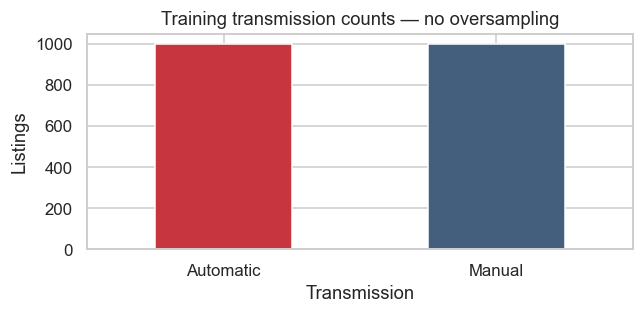

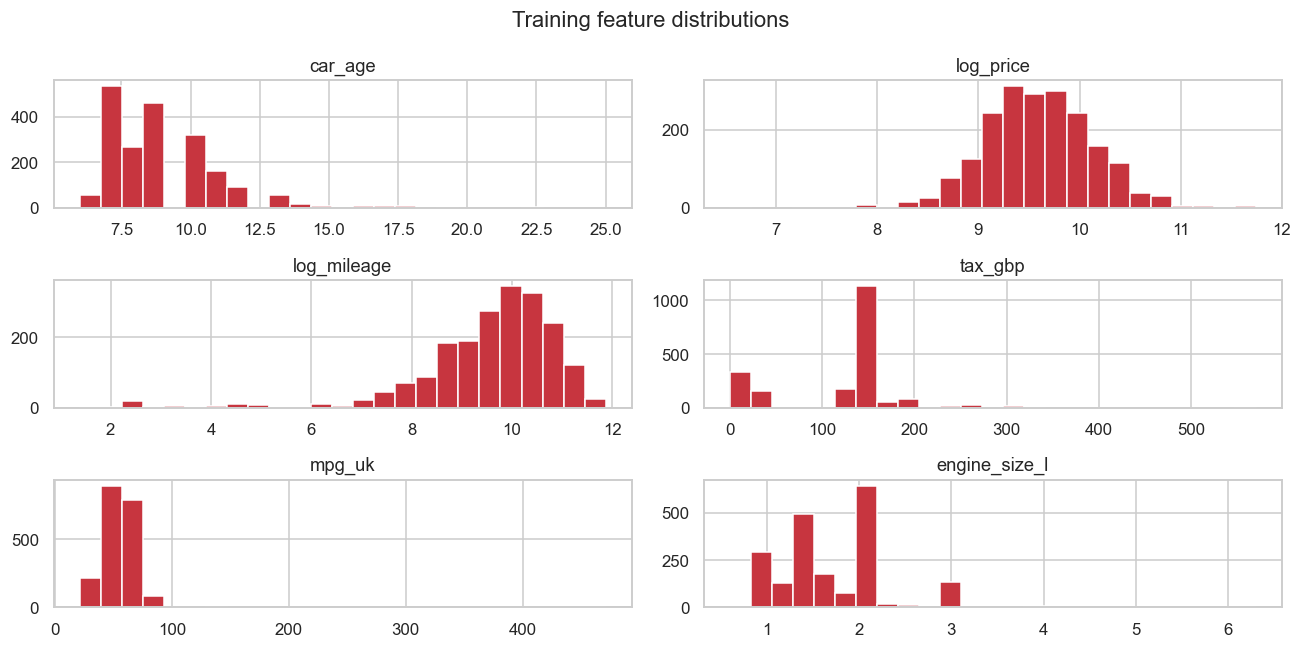

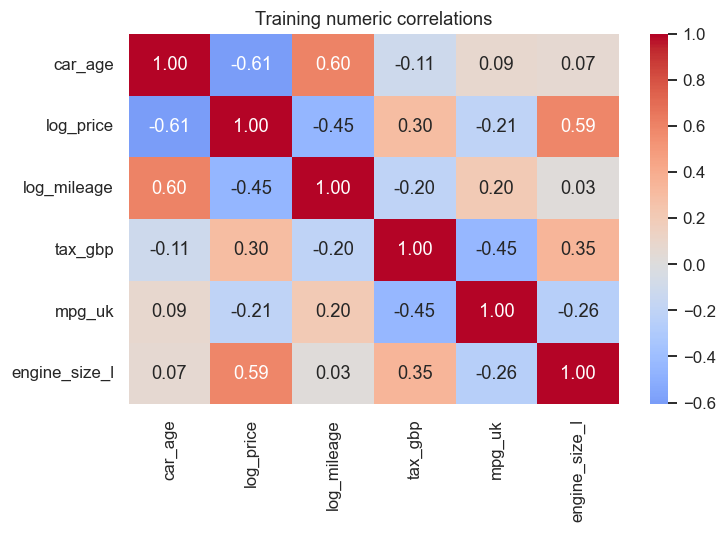

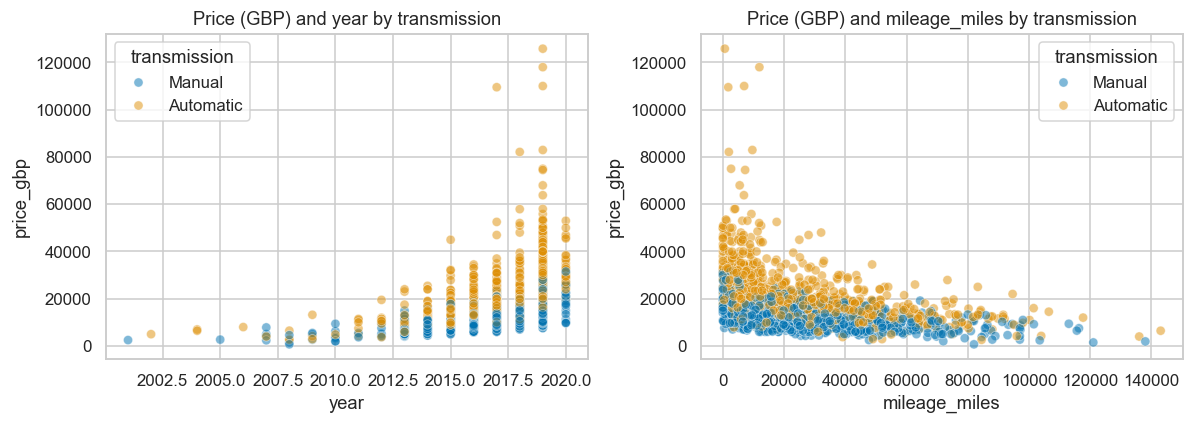

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
brand,2000,9,Ford,312,NaN,NaN,NaN,NaN,NaN,NaN,NaN
model,2000,143,Fiesta,118,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,2000.0,NaN,NaN,NaN,2016.9735,2.129569,2001.0,2016.0,2017.0,2019.0,2020.0
price_gbp,2000.0,NaN,NaN,NaN,17001.7955,10392.673128,694.0,10417.25,14492.0,20900.0,125796.0
mileage_miles,2000.0,NaN,NaN,NaN,24529.251,21740.610165,3.0,8121.75,18820.0,34000.0,143000.0
fuel_type,2000,4,Petrol,1001,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tax_gbp,2000.0,NaN,NaN,NaN,120.4075,67.327468,0.0,125.0,145.0,145.0,570.0
mpg_uk,2000.0,NaN,NaN,NaN,55.725,17.138348,21.4,46.3,55.4,63.15,470.8
engine_size_l,2000.0,NaN,NaN,NaN,1.7235,0.577472,0.6,1.4,1.6,2.0,6.3
transmission,2000,2,Manual,1000,NaN,NaN,NaN,NaN,NaN,NaN,NaN


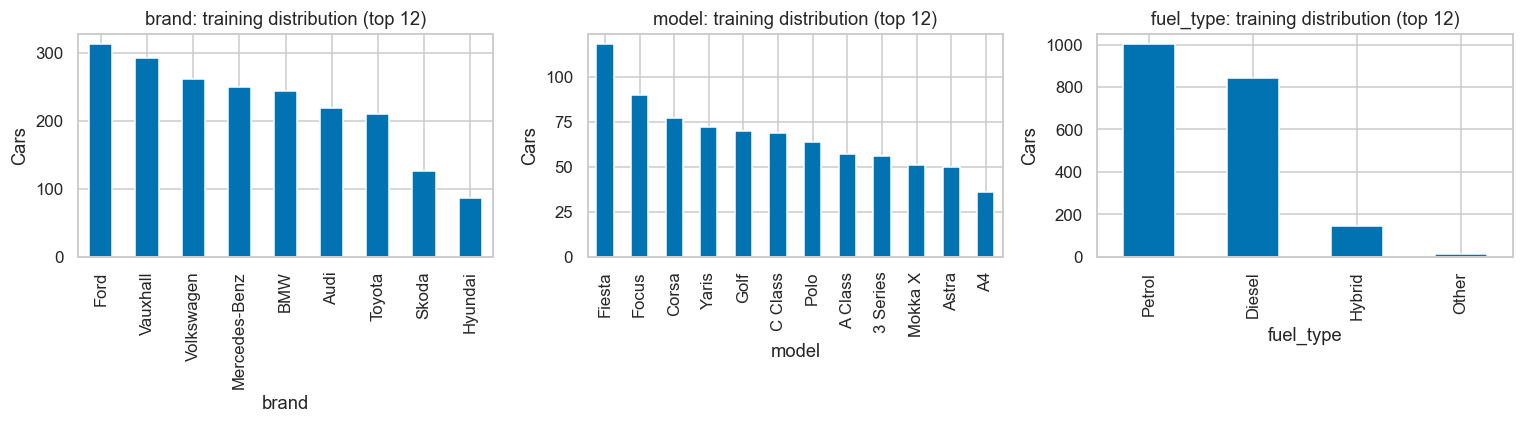

In [3]:
audit_plots(df, train)
display(train.describe(include="all").T)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
engineered_train = CarFeatures().transform(X_train)
for axis, column in zip(axes.ravel(), ["brand", "model", "fuel_type"]):
    engineered_train[column].value_counts().head(12).plot.bar(ax=axis)
    axis.set(
        title=f"{column}: training distribution (top 12)",
        xlabel=column,
        ylabel="Cars",
    )
plt.tight_layout()
plt.show()


## 4. Model training and tuning

The first cell evaluates the untuned baseline. The second uses GridSearchCV; the search includes the baseline settings, and lower held-out performance is reported honestly.

In [4]:
slug = "random_forest"
name, estimator, parameter_grid = configurations()[slug]
print("Baseline estimator:")
display(estimator)
print("Parameter grid:")
display(parameter_grid)

baseline = build_pipeline(clone(estimator))
warning_messages = []
with warnings.catch_warnings(record=True) as captured:
    warnings.simplefilter("always")
    baseline_cv = cross_validate(
        baseline,
        X_train,
        y_train,
        cv=CV,
        scoring=SCORING,
        n_jobs=1,
        error_score="raise",
    )
    baseline.fit(X_train, y_train)

warning_messages.extend(str(item.message) for item in captured)
display(
    pd.DataFrame(
        {key: value for key, value in baseline_cv.items() if key.startswith("test_")}
    )
)
print("Mean baseline CV macro F1:", baseline_cv["test_f1_macro"].mean())

Baseline estimator:
Parameter grid:
Mean baseline CV macro F1: 0.8549557420459012


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

[{'model__n_estimators': [100],
  'model__max_depth': [None],
  'model__min_samples_leaf': [1]},
 {'model__n_estimators': [150, 250],
  'model__max_depth': [8, None],
  'model__min_samples_leaf': [2]}]

,test_f1_macro,test_f1_weighted,test_balanced_accuracy
0,0.877493,0.877493,0.8775
1,0.852477,0.852477,0.8525
2,0.837418,0.837418,0.8375
3,0.864916,0.864916,0.8650
4,0.842475,0.842475,0.8425


In [5]:
search = GridSearchCV(
    build_pipeline(clone(estimator)),
    parameter_grid,
    scoring=SCORING,
    refit="f1_macro",
    cv=CV,
    n_jobs=1,
    error_score="raise",
    return_train_score=False,
)
with warnings.catch_warnings(record=True) as captured:
    warnings.simplefilter("always")
    search.fit(X_train, y_train)

warning_messages.extend(str(item.message) for item in captured)
tuned = search.best_estimator_
print("Best parameters:", search.best_params_)
print("Best training CV macro F1:", search.best_score_)
display(
    pd.DataFrame(search.cv_results_)[
        [
            "params",
            "mean_test_f1_macro",
            "std_test_f1_macro",
            "mean_test_f1_weighted",
            "rank_test_f1_macro",
        ]
    ].sort_values("rank_test_f1_macro")
)
print("Recorded training warnings:", sorted(set(warning_messages)) or "None")

Best parameters: {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 100}
Best training CV macro F1: 0.8549557420459012
Recorded training warnings: None


,params,mean_test_f1_macro,std_test_f1_macro,mean_test_f1_weighted,rank_test_f1_macro
0,"{'model__max_depth': None, 'model__min_samples...",0.854956,0.014674,0.854956,1
4,"{'model__max_depth': None, 'model__min_samples...",0.833914,0.021417,0.833914,2
3,"{'model__max_depth': None, 'model__min_samples...",0.832921,0.023248,0.832921,3
1,"{'model__max_depth': 8, 'model__min_samples_le...",0.821478,0.024525,0.821478,4
2,"{'model__max_depth': 8, 'model__min_samples_le...",0.817981,0.027355,0.817981,5


## 5. Evaluation

,Model,Stage,Accuracy,Precision_weighted,Recall_weighted,F1_weighted,F1_macro,Balanced_accuracy,Automatic_precision,Automatic_recall,ROC_AUC,Average_precision_Automatic,CV_macro_F1,CV_macro_F1_std
0,Random Forest,Before tuning,0.868,0.8692,0.868,0.8679,0.8679,0.868,0.8898,0.84,0.9347,0.9403,0.855,0.0147
1,Random Forest,After tuning,0.868,0.8692,0.868,0.8679,0.8679,0.868,0.8898,0.84,0.9347,0.9403,0.855,0.0147


,After minus before
Accuracy,0.0
F1_weighted,0.0
F1_macro,0.0
Automatic_recall,0.0
ROC_AUC,0.0
CV_macro_F1,0.0


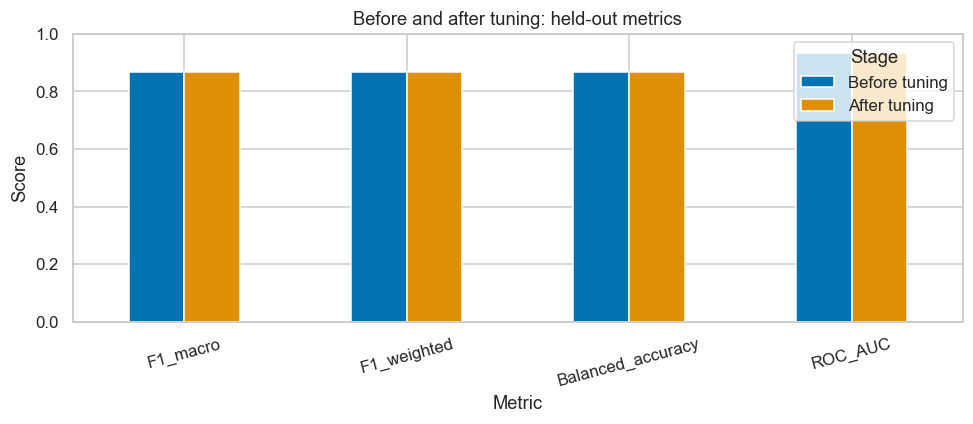

In [6]:
comparison = evaluate_pair(
    slug,
    name,
    baseline,
    tuned,
    X_test,
    y_test,
    baseline_cv,
    search,
    warning_messages,
)
display(comparison.round(4))

metric_columns = [
    "Accuracy",
    "F1_weighted",
    "F1_macro",
    "Automatic_recall",
    "ROC_AUC",
    "CV_macro_F1",
]
delta = comparison.loc[1, metric_columns] - comparison.loc[0, metric_columns]
display(delta.to_frame("After minus before"))

comparison.set_index("Stage")[
    ["F1_macro", "F1_weighted", "Balanced_accuracy", "ROC_AUC"]
].T.plot.bar(figsize=(9, 4), ylim=(0, 1))
plt.title("Before and after tuning: held-out metrics")
plt.xlabel("Metric")
plt.ylabel("Score")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 6. Confusion matrix and model interpretation

,precision,recall,f1-score,support
Automatic,0.8898,0.840,0.8642,250.000
Manual,0.8485,0.896,0.8716,250.000
accuracy,0.8680,0.868,0.8680,0.868
macro avg,0.8692,0.868,0.8679,500.000
weighted avg,0.8692,0.868,0.8679,500.000


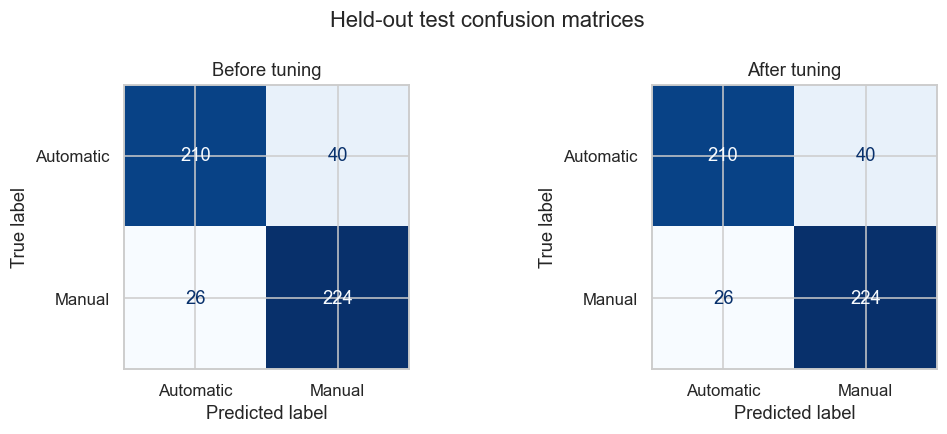

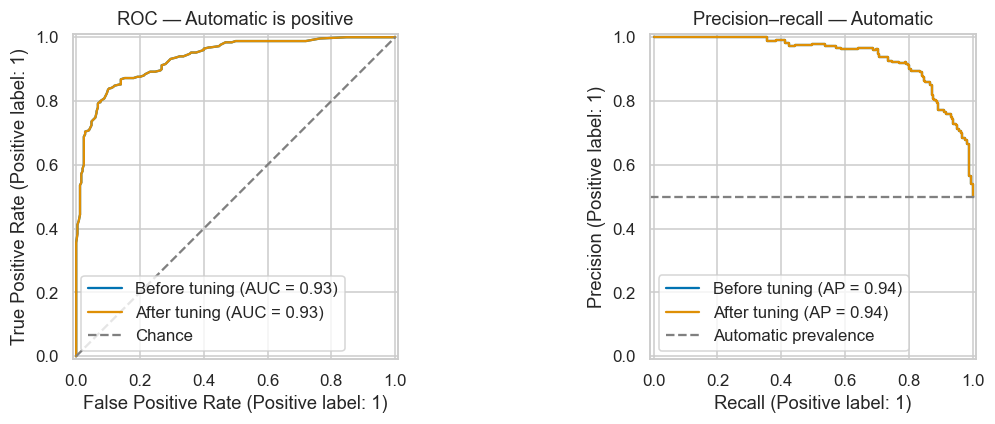

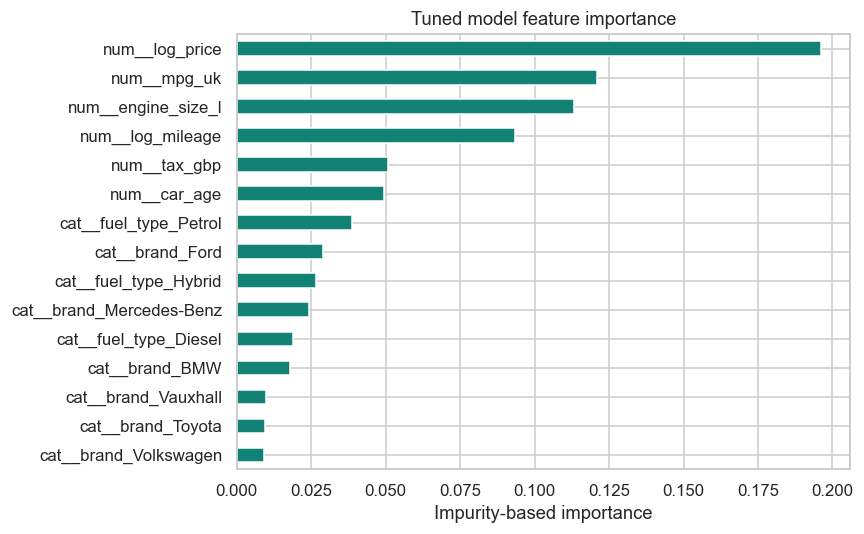

In [ ]:
display(
    pd.read_csv(
        ROOT / "results" / slug / "after_class_report.csv", index_col=0
    ).round(4)
)
plot_pair(slug, baseline, tuned, X_test, y_test)

## 7. Observation / Interpretation

**Observation:** This notebook compares the baseline and CV-selected **Random Forest** classifier on one untouched test split.

- Identify the metric that changed most and report the exact after-minus-before value.
- Compare Automatic-class errors in the two confusion matrices.
- Explain how the selected hyperparameters affect this model's learning mechanism.
- Explain why a CV improvement may not produce a held-out improvement.
- Discuss why oversampling is unnecessary for this balanced dataset.

Models and numeric results are exported to `models/` and `results/`; the GUI reads those same files.
Complete the interpretation using the executed evidence and your own wording.